# Set 9: EDA + Fuzzy C-Means

**Q1 → Exp 1A / 1B / 2** · **Q2 → Exp 7** (Fuzzy C-Means)

Datasets: `IRIS.csv` for both.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/IRIS.csv")
print(df.shape)
df.head()

(150, 5)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Q1.2 5-number summary, correlated with a box plot

     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
min            4.3           2.0           1.00           0.1
25%            5.1           2.8           1.60           0.3
50%            5.8           3.0           4.35           1.3
75%            6.4           3.3           5.10           1.8
max            7.9           4.4           6.90           2.5


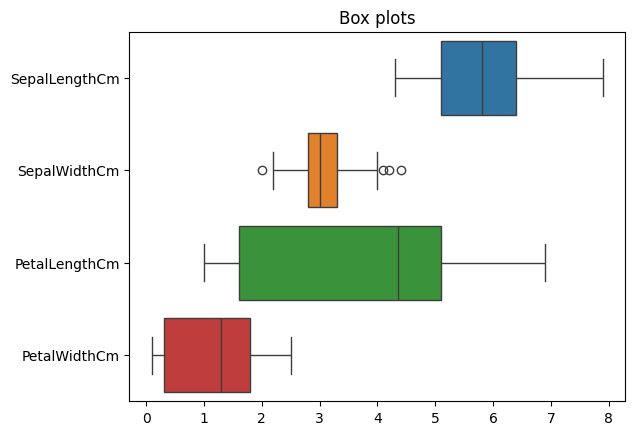

In [3]:
num = df.select_dtypes("number")
print(num.describe().loc[["min", "25%", "50%", "75%", "max"]])   # 5-number summary of every numeric column

sns.boxplot(data=num, orient="h")
plt.title("Box plots")
plt.show()

**Correlate with the box plot:** left edge of the box = 25%, middle line = 50% (median), right edge = 75%, whiskers reach towards min and max, and dots beyond the whiskers are outliers.

### Q1.3 Multivariate analysis (pair plot)

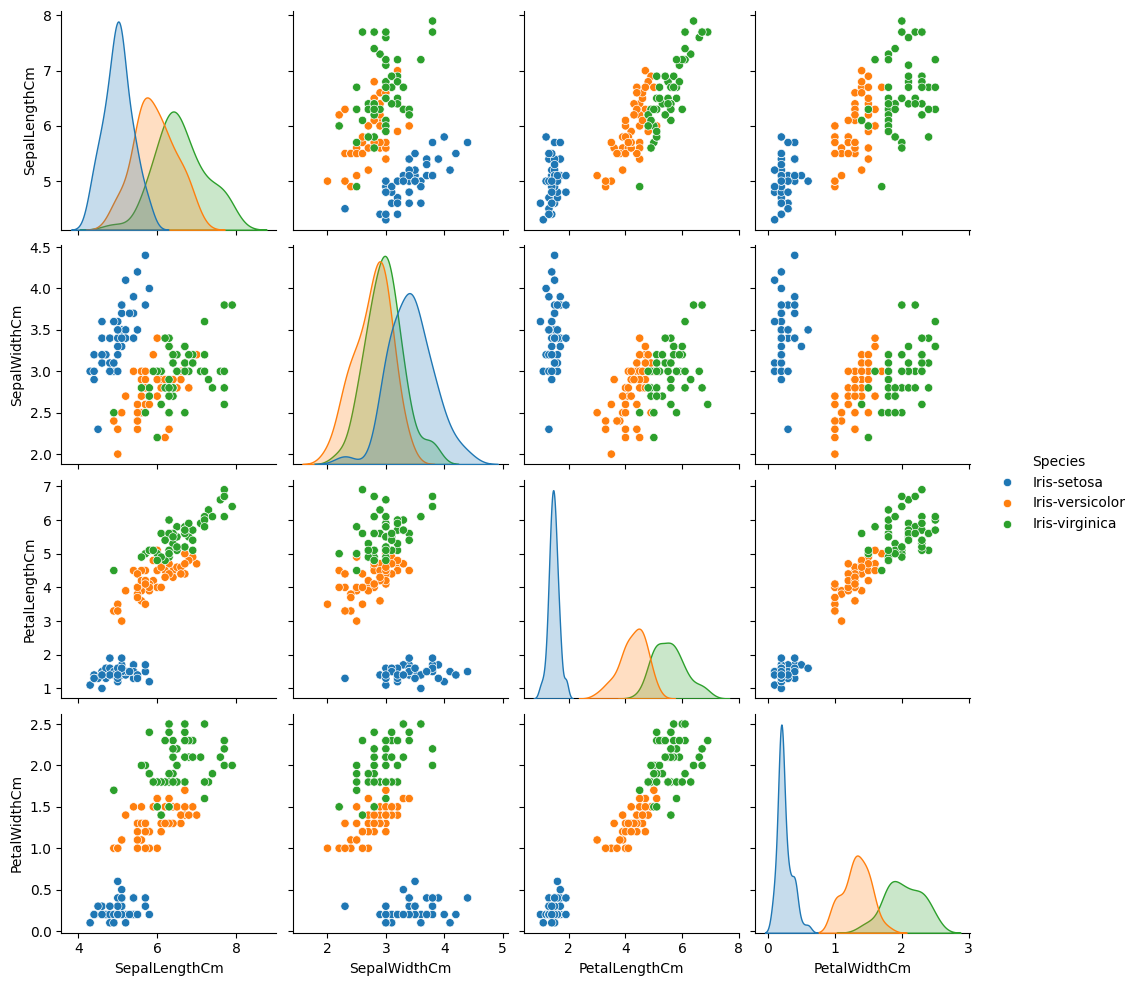

In [4]:
sns.pairplot(df, hue="Species")
plt.show()

### Q1.4 Min-max normalisation of a numerical feature (Python code)
The paper says `'Age'`, but IRIS has no Age column, so this uses `SepalLengthCm`. The formula is the same.

In [5]:
col = "SepalLengthCm"
df[col + "_minmax"] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())    # now between 0 and 1
df[[col, col + "_minmax"]].describe().loc[["min", "max"]]

,SepalLengthCm,SepalLengthCm_minmax
min,4.3,0.0
max,7.9,1.0


### Q1.5 LDA for feature extraction

Explained variance: [0.991 0.009]


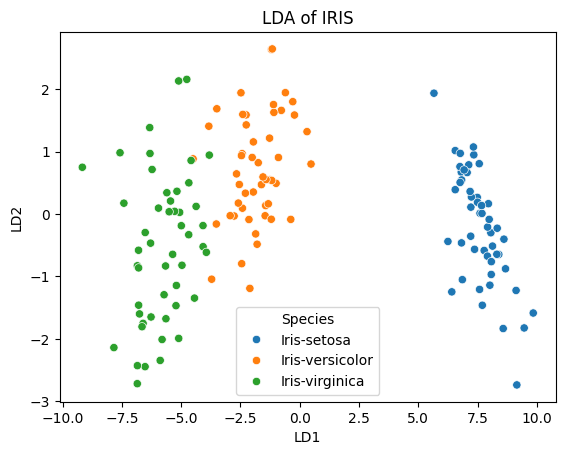

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
lda = LinearDiscriminantAnalysis(n_components=2)
ld = lda.fit_transform(X, df["Species"])            # LDA uses the labels (PCA doesn't)
print("Explained variance:", lda.explained_variance_ratio_.round(3))
sns.scatterplot(x=ld[:, 0], y=ld[:, 1], hue=df["Species"])
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA of IRIS")
plt.show()

---
## Question 2

### Q2.1 Read the data and preprocess

In [7]:
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/IRIS.csv")
X = StandardScaler().fit_transform(df.drop(columns="Species"))   # clustering never sees the answer column
print(X.shape)

(150, 4)


### The FCM function (the same as Exp7_SHORT)

In [8]:
def fcm(X, c, m=2):
    U = np.random.default_rng(42).random((c, len(X)))
    U = U / U.sum(axis=0)                                            # every column sums to 1
    for it in range(1, 301):
        U_old = U.copy()
        Um = U ** m
        centroids = (Um @ X) / Um.sum(axis=1, keepdims=True)         # weighted average of the points
        d = np.linalg.norm(X[None] - centroids[:, None], axis=2)     # distance of every point to every centroid
        U = 1 / np.sum((d[:, None] / d[None]) ** (2 / (m - 1)), axis=1)
        if np.linalg.norm(U - U_old) < 1e-5:
            break
    return centroids, U

def pc_score(U):
    return np.sum(U ** 2) / U.shape[1]            # partition coefficient: higher = better

def ce_score(U):
    return -np.sum(U * np.log(U)) / U.shape[1]    # classification entropy: lower = better

### Q2.2 Determine the optimal number of clusters
### Q2.4 Measure performance with Partition Coefficient and Classification Entropy

*One code cell below answers both parts.*

In [9]:
rows = []
for c in range(2, 7):
    centroids, U = fcm(X, c)
    rows.append([c, pc_score(U), ce_score(U)])
scores = pd.DataFrame(rows, columns=["c", "PC (higher better)", "CE (lower better)"])
print(scores.round(4))
best = int(scores.loc[scores["PC (higher better)"].idxmax(), "c"])
print("Optimal number of clusters:", best)

   c  PC (higher better)  CE (lower better)
0  2              0.8339             0.2869
1  3              0.7065             0.5294
2  4              0.6341             0.6902
3  5              0.5700             0.8398
4  6              0.5117             0.9877
Optimal number of clusters: 2


### Q2.3 Print and plot the cluster centroids and cluster labels

Centroids:
 [[ 0.579 -0.364  0.692  0.673]
 [-0.974  0.741 -1.218 -1.175]]
Labels: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


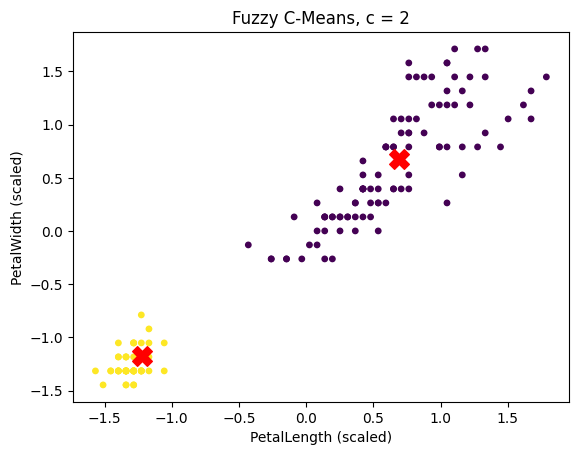

In [10]:
centroids, U = fcm(X, best)
labels = U.argmax(axis=0)               # each point goes to the cluster it belongs to MOST
print("Centroids:\n", centroids.round(3))
print("Labels:", labels)

plt.scatter(X[:, 2], X[:, 3], c=labels, s=15)
plt.scatter(centroids[:, 2], centroids[:, 3], c="red", marker="X", s=200)
plt.xlabel("PetalLength (scaled)")
plt.ylabel("PetalWidth (scaled)")
plt.title(f"Fuzzy C-Means, c = {best}")
plt.show()

**Viva:** IRIS has 3 species, but PC picks **2** clusters, because setosa sits far away while versicolor and virginica overlap. PC says "2 clean groups" beats "3 fuzzy groups".